# Perfilado, contrato de calidad, cuarentena y fuente externa (P2, M2)

**Responsable:** Persona 2 · **Entrega 1** · Requiere `uv run novaretail all` antes de ejecutar.

Este notebook solo **llama** a `novaretail.ingest`, `novaretail.contracts` y `novaretail.external_api` y muestra resultados.
Las tablas y figuras que se marcan con /fig/ van a la memoria (apartados 3.1–3.4).

In [1]:
%load_ext autoreload
%autoreload 2

import json
import matplotlib.pyplot as plt
import pandas as pd

from novaretail import contracts, ingest
from novaretail.config import FIGURES, META

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
FIGURES.mkdir(parents=True, exist_ok=True)

# estilo común de las figuras de la memoria
INK, MUTED, GRID = "#1f1f1e", "#6b6b68", "#e6e6e3"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#a3a39e"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Perfilado de cada dataset (capa bronze)

Qué llega de cada fuente antes de tocar nada: volumen, nulos, duplicados y rango de fechas.

In [ ]:
raw = {
    "orders": ingest.load_orders(),
    "sales": ingest.load_sales(),
    "fulfilment_events": ingest.load_events(),
    "inventory_weekly": ingest.load_inventory(),
    "tickets": ingest.load_tickets(),
    "customers": ingest.load_customers(),
    "products": ingest.load_products(),
    "stores": ingest.load_stores(),
}
date_col = {"orders": "created_ts", "sales": "sale_ts", "fulfilment_events": "event_ts", "inventory_weekly": "week",
            "tickets": "created_ts", "customers": "signup_date"}

def profile(name, df):
    d = pd.to_datetime(df[date_col[name]], errors="coerce", format="ISO8601") if name in date_col else None
    return {
        "dataset": name,
        "filas": len(df),
        "columnas": df.shape[1],
        "celdas nulas %": df.isna().mean().mean() * 100,
        "filas duplicadas": int(df.duplicated().sum()),
        "fecha mín": d.min().date() if d is not None else None,
        "fecha máx": d.max().date() if d is not None else None,
        "fechas no ISO": int(d.isna().sum() - df[date_col[name]].isna().sum()) if d is not None else None,
    }

perfil = pd.DataFrame([profile(n, d) for n, d in raw.items()]).set_index("dataset")
perfil  # /fig/ Tabla 3.x

,filas,columnas,celdas nulas %,filas duplicadas,fecha mín,fecha máx,fechas no ISO
dataset,,,,,,,
orders,80224,10,0.53,1180,2025-01-01,2027-10-28,795.00
sales,141563,10,0.00,0,2025-01-01,2026-10-31,0.00
fulfilment_events,230773,6,0.05,915,2024-12-31,2026-10-31,0.00
inventory_weekly,501984,6,0.00,0,2024-12-30,2026-10-26,0.00
tickets,3663,4,0.00,0,2025-01-04,2026-10-31,0.00
customers,30000,11,0.00,0,2023-01-03,2026-10-30,0.00
products,400,6,0.00,0,None,None,NaN
stores,40,7,0.00,0,None,None,NaN


In [3]:
# detalle de pedidos: nulos y valores distintos por columna
o = raw["orders"]
pd.DataFrame({"nulos": o.isna().sum(), "vacíos": (o == "").sum(), "distintos": o.nunique()})

,nulos,vacíos,distintos
order_id,0,0,78651
customer_id,0,0,21212
store,400,0,80
channel,0,0,14
created_ts,0,0,78955
promised_ts,0,0,78573
delivered_ts,1389,0,72330
status,238,0,6
revenue_eur,0,0,27957
variable_cost_eur,2257,0,23927


In [4]:
print("Etiquetas de canal en bruto:", sorted(o["channel"].dropna().unique()))
print("Estados en bruto:", o["status"].value_counts(dropna=False).to_dict())

Etiquetas de canal en bruto: [' web', 'APP', 'App', 'Marketplace', 'TIENDA', 'Tienda', 'WEB ', 'Web', 'app', 'market_place', 'marketplace', 'store', 'tienda', 'web']
Estados en bruto: {'delivered': 71199, 'returned': 7401, 'cancelled': 1181, nan: 238, 'shipped': 118, 'pending': 49, 'processing': 38}


## 2. Contrato de calidad y cuarentena (bronze → silver)

Mismo orden que `uv run novaretail validate`: primero `sales`, porque sus líneas válidas sirven para conciliar el importe de cada pedido.

In [ ]:
sales, sales_q, r_sales = contracts.clean_sales(raw["sales"], raw["products"])
orders, orders_q, r_orders = contracts.clean_orders(raw["orders"], sales, sales_q)
events, events_q, r_events = contracts.clean_events(raw["fulfilment_events"])
inv, inv_q, r_inv = contracts.clean_inventory(raw["inventory_weekly"])
reports = {r.dataset: r for r in [r_orders, r_sales, r_events, r_inv]}

resumen = pd.DataFrame([{
    "dataset": r.dataset, "filas entrada": r.rows_in, "corregidas/eliminadas": sum(r.corrections.values()),
    "cuarentena": r.rows_quarantined, "cuarentena %": r.quarantine_rate * 100, "válidas": r.rows_valid,
    "regla crítica": "; ".join(r.critical) or "OK"} for r in reports.values()]).set_index("dataset")
resumen  # /fig/ Tabla 3.x

,filas entrada,corregidas/eliminadas,cuarentena,cuarentena %,válidas,regla crítica
dataset,,,,,,
orders,80224,4335,4099,5.11,74945,OK
sales,141563,0,846,0.60,140717,OK
fulfilment_events,230773,2061,662,0.29,229195,OK
inventory_weekly,501984,0,501,0.10,501483,OK


In [ ]:
motivos = pd.DataFrame([
    {"dataset": r.dataset, "tipo": tipo, "motivo": k, "filas": v}
    for r in reports.values()
    for tipo, dct in [("corrección", r.corrections), ("cuarentena", r.quarantine_by_reason), ("aviso", r.warnings)]
    for k, v in dct.items() if v
]).sort_values(["dataset", "tipo", "filas"], ascending=[True, True, False])
motivos.reset_index(drop=True)  #  Anexo: detalle de reglas

,dataset,tipo,motivo,filas
0,fulfilment_events,aviso,pedidos_con_secuencia_incoherente,128
1,fulfilment_events,corrección,eventos_duplicados_eliminados,916
2,fulfilment_events,corrección,transportista_deducido,686
3,fulfilment_events,corrección,actividad_en_minusculas,459
4,fulfilment_events,cuarentena,secuencia_incoherente,659
5,fulfilment_events,cuarentena,carrier:not_nullable,3
6,inventory_weekly,aviso,semanas_faltantes,2016
7,inventory_weekly,cuarentena,on_hand_units:stock_no_negativo,501
8,orders,aviso,pedido_no_conciliable_por_lineas_en_cuarentena,815
9,orders,corrección,canal_normalizado,1577


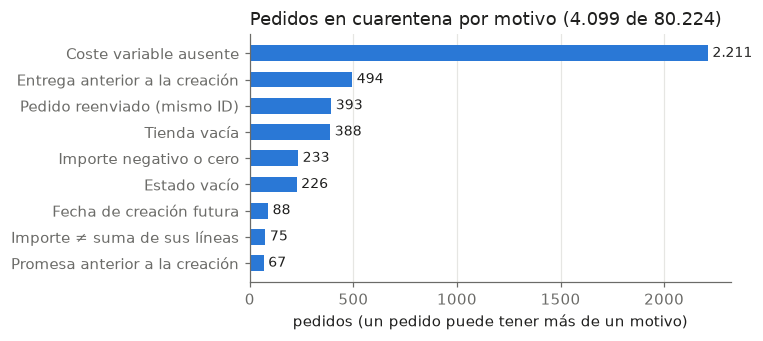

In [ ]:
# Figura: motivos de cuarentena en pedidos
NOMBRES = {"coste_ausente": "Coste variable ausente", "fila:entrega_tras_creacion": "Entrega anterior a la creación",
           "order_id_reenviado": "Pedido reenviado (mismo ID)", "store:not_nullable": "Tienda vacía",
           "revenue_eur:importe_positivo": "Importe negativo o cero", "status:not_nullable": "Estado vacío",
           "fecha_futura": "Fecha de creación futura", "importe_no_cuadra_con_lineas": "Importe ≠ suma de sus líneas",
           "fila:promesa_tras_creacion": "Promesa anterior a la creación"}
q = pd.Series(r_orders.quarantine_by_reason).rename(index=NOMBRES).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(q.index, q.values, color=BLUE, height=0.6)
for y, v in enumerate(q.values):
    ax.text(v + q.max() * 0.01, y, f"{v:,}".replace(",", "."), va="center", color=INK, fontsize=9)
ax.set_xlabel("pedidos (un pedido puede tener más de un motivo)")
ax.grid(axis="x", color=GRID); ax.set_axisbelow(True)
ax.set_title(f"Pedidos en cuarentena por motivo ({r_orders.rows_quarantined:,} de {r_orders.rows_in:,})".replace(",", "."),
             loc="left", color=INK)
fig.tight_layout(); fig.savefig(FIGURES / "p2_cuarentena_motivos.png", bbox_inches="tight")

### Cobertura del contrato

Comprobación de que el contrato detecta los errores que inyectó el generador (`data/_meta`, **solo para verificar**, nunca como dato de entrada). Las diferencias pequeñas se deben a filas con dos errores a la vez, que se cuentan una sola vez.

In [ ]:
cobertura = contracts.coverage_vs_injected(reports, META / "generation_info.json")
cobertura  # /fig/ Tabla 3.x

,dataset,error_inyectado,inyectados,tratamiento,regla,detectados,cubierto
0,orders,duplicate_exact_rows,1180,corrección,duplicados_exactos_eliminados,1180,True
1,orders,duplicate_order_id_resent,393,cuarentena,order_id_reenviado,393,True
2,orders,variable_cost_missing,2214,cuarentena,coste_ausente,2211,True
3,orders,delivered_before_created,444,cuarentena,fila:entrega_tras_creacion,494,True
4,orders,created_ts_alt_format,787,corrección,fecha_formato_europeo,787,True
5,orders,created_ts_future,157,cuarentena,fecha_futura + fila:promesa_tras_creacion,155,True
6,orders,channel_inconsistent_label,1573,corrección,canal_normalizado,1577,True
7,orders,revenue_negative,236,cuarentena,revenue_eur:importe_positivo,233,True
8,orders,revenue_outlier_x100,79,cuarentena,importe_no_cuadra_con_lineas,75,True
9,orders,store_null,393,cuarentena,store:not_nullable,388,True


In [9]:
print(f"Errores cubiertos: {cobertura['cubierto'].sum()} de {len(cobertura)}")

Errores cubiertos: 21 de 21


## 3. KPI ingenuo vs. validado (M2)

**Ingenuo** = lo que calcula hoy el dashboard diario: suma directa de `orders.csv` tal como llega.
**Validado** = mismo cálculo sobre los pedidos que cumplen el contrato. Los pedidos con coste ausente **no se imputan**: se excluyen y se informa.

In [ ]:
def to_num(df):
    d = df.copy()
    for c in ["revenue_eur", "variable_cost_eur"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    for c in ["created_ts", "promised_ts", "delivered_ts"]:
        d[c] = pd.to_datetime(d[c], errors="coerce", format="mixed")
    return d

def kpis(d):
    online = d[d["channel"].isin(["web", "app", "marketplace"]) & (d["status"] == "delivered")]
    return pd.Series({
        "pedidos": len(d),
        "ingresos (€)": d["revenue_eur"].sum(),
        "margen de contribución (€)": (d["revenue_eur"] - d["variable_cost_eur"]).sum(),
        "margen (%)": (d["revenue_eur"] - d["variable_cost_eur"]).sum() / d["revenue_eur"].sum() * 100,
        "ticket medio (€)": d["revenue_eur"].mean(),
        "entrega a tiempo online (%)": (online["delivered_ts"] <= online["promised_ts"]).mean() * 100,
    })

naive = to_num(raw["orders"])
comp = pd.DataFrame({"ingenuo": kpis(naive), "validado": kpis(orders)})
comp["diferencia (%)"] = (comp["ingenuo"] / comp["validado"] - 1) * 100
comp  # /fig/ Tabla M2

,ingenuo,validado,diferencia (%)
pedidos,"80,224.00","74,945.00",7.04
ingresos (€),"10,274,866.03","8,766,354.59",17.21
margen de contribución (€),"2,785,529.66","1,899,680.98",46.63
margen (%),27.11,21.67,25.10
ticket medio (€),128.08,116.97,9.50
entrega a tiempo online (%),84.32,84.09,0.27


In [11]:
# De dónde sale la diferencia de ingresos: puente ingenuo -> validado
dups = naive[naive.duplicated()]["revenue_eur"].sum()
oq = orders_q.copy()
oq["revenue_eur"] = pd.to_numeric(oq["revenue_eur"], errors="coerce")
oq["motivo"] = oq["quarantine_reason"].str.split(";").str[0]
grupo = {"importe_no_cuadra_con_lineas": "Importes ×100", "coste_ausente": "Coste ausente",
         "order_id_reenviado": "Pedidos reenviados", "revenue_eur:importe_positivo": "Importes negativos"}
oq["causa"] = oq["motivo"].map(grupo).fillna("Campos inválidos")
puente = pd.concat([pd.Series({"Duplicados exactos": dups}), oq.groupby("causa")["revenue_eur"].sum()])
puente = puente.sort_values(key=lambda s: -s.abs())
check = comp.loc["ingresos (€)", "ingenuo"] - puente.sum() - comp.loc["ingresos (€)", "validado"]
print(f"Cuadre del puente: {check:,.2f} €")
puente.rename("ingresos retirados (€)").to_frame()  # 📄

Cuadre del puente: 0.00 €


,ingresos retirados (€)
Importes ×100,"854,068.00"
Coste ausente,"315,248.20"
Duplicados exactos,"163,202.82"
Campos inválidos,"143,396.42"
Pedidos reenviados,"62,075.74"
Importes negativos,"-29,479.74"


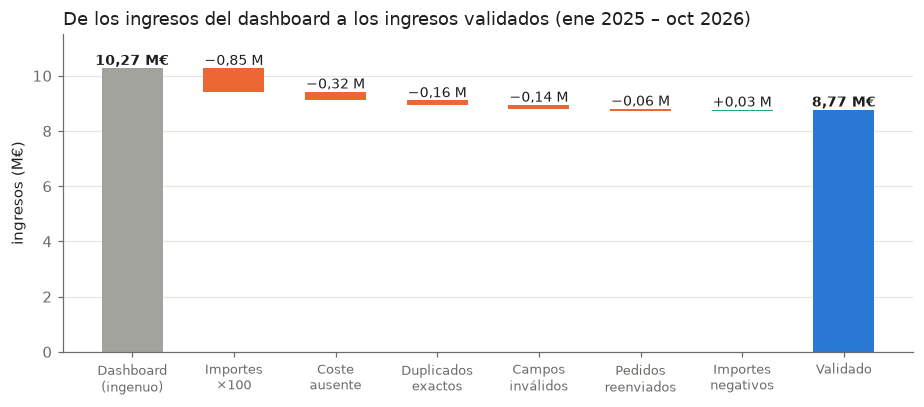

In [ ]:
# /fig/ Figura: puente de ingresos (cascada)
start, end = comp.loc["ingresos (€)", "ingenuo"], comp.loc["ingresos (€)", "validado"]
labels = ["Dashboard\n(ingenuo)"] + [l.replace(" ", "\n", 1) for l in puente.index] + ["Validado"]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
level = start
ax.bar(0, start / 1e6, color=GREY, width=0.6)
for i, v in enumerate(puente.values, start=1):
    ax.bar(i, -v / 1e6, bottom=level / 1e6, color=ORANGE if v > 0 else "#1baf7a", width=0.6)
    top = max(level, level - v)
    sign = "−" if v > 0 else "+"
    ax.text(i, top / 1e6 + 0.12, f"{sign}{abs(v)/1e6:,.2f} M".replace(".", ","), ha="center", color=INK, fontsize=9)
    level -= v
ax.bar(len(labels) - 1, end / 1e6, color=BLUE, width=0.6)
for x, v in [(0, start), (len(labels) - 1, end)]:
    ax.text(x, v / 1e6 + 0.12, f"{v/1e6:,.2f} M€".replace(".", ","), ha="center", color=INK, fontsize=9, weight="bold")
ax.set_xticks(range(len(labels)), labels, fontsize=8.5)
ax.set_ylabel("ingresos (M€)"); ax.set_ylim(0, start / 1e6 * 1.12)
ax.grid(axis="y", color=GRID); ax.set_axisbelow(True)
ax.set_title("De los ingresos del dashboard a los ingresos validados (ene 2025 – oct 2026)", loc="left", color=INK)
fig.tight_layout(); fig.savefig(FIGURES / "p2_puente_ingresos.png", bbox_inches="tight")

In [13]:
# Margen por canal: en bruto (solo unificando la etiqueta de canal) vs. validado
nb = naive.assign(channel=naive["channel"].str.strip().str.lower().replace(contracts.CHANNEL_FIXES))
def margin(d):
    return d.groupby("channel").apply(lambda g: (g["revenue_eur"] - g["variable_cost_eur"]).sum() / g["revenue_eur"].sum() * 100,
                                      include_groups=False)
mc = pd.DataFrame({"bruto": margin(nb), "validado": margin(orders)}).reindex(["tienda", "web", "app", "marketplace"])
print("Etiquetas de canal distintas en el dashboard actual:", naive["channel"].nunique())
mc  # 📄

Etiquetas de canal distintas en el dashboard actual: 14


,bruto,validado
channel,,
tienda,32.32,27.93
web,23.53,20.48
app,28.44,20.31
marketplace,14.56,2.11


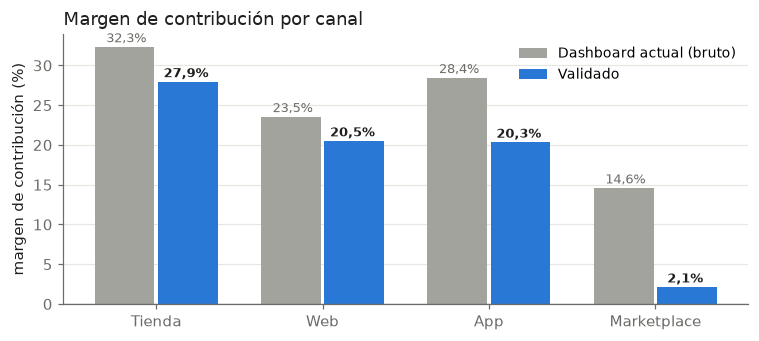

In [ ]:
# /fig/ Figura: margen de contribución por canal
fig, ax = plt.subplots(figsize=(7, 3.2))
x = range(len(mc))
w = 0.36
ax.bar([i - w / 2 - 0.01 for i in x], mc["bruto"], width=w, color=GREY, label="Dashboard actual (bruto)")
ax.bar([i + w / 2 + 0.01 for i in x], mc["validado"], width=w, color=BLUE, label="Validado")
for i, (b, v) in enumerate(zip(mc["bruto"], mc["validado"])):
    ax.text(i - w / 2, b + 0.6, f"{b:.1f}%".replace(".", ","), ha="center", fontsize=8.5, color=MUTED)
    ax.text(i + w / 2, v + 0.6, f"{v:.1f}%".replace(".", ","), ha="center", fontsize=8.5, color=INK, weight="bold")
ax.set_xticks(list(x), [c.capitalize() for c in mc.index])
ax.set_ylabel("margen de contribución (%)"); ax.axhline(0, color=MUTED, lw=0.8)
ax.grid(axis="y", color=GRID); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.set_title("Margen de contribución por canal", loc="left", color=INK)
fig.tight_layout(); fig.savefig(FIGURES / "p2_margen_canal.png", bbox_inches="tight")

## 4. Fuente externa vía API: Open-Meteo

Temperatura y precipitación diarias de las 12 ciudades con tienda, validadas con el contrato `DailyWeather`. Si la API no responde se usa la caché; si no hay ni API ni caché, se avisa y el resto del notebook sigue.

In [15]:
from novaretail.external_api import CITIES, ExternalSourceError, load_weather

try:
    weather, origen = load_weather(refresh=False) if (ingest.RAW / "external_weather.parquet").exists() else load_weather()
    print(f"Origen: {origen} · {len(weather):,} registros · {weather['city'].nunique()} ciudades")
except ExternalSourceError as exc:
    weather = None
    print("Fuente externa no disponible:", exc)

Origen: cache · 8,028 registros · 12 ciudades


In [ ]:
if weather is not None:
    stores = ingest.load_stores()
    s = sales.merge(stores[["store_id", "city"]], on="store_id")
    s = s[s["channel"] == "tienda"].assign(day=s["sale_ts"].dt.normalize())
    daily = s.groupby(["city", "day"])["units"].sum().reset_index()
    w = weather.assign(day=pd.to_datetime(weather["day"]), lluvia=weather["precipitation_mm"] >= 5)
    j = daily.merge(w, on=["city", "day"])
    display(j.groupby("lluvia")["units"].mean().rename("unidades/día en tienda").to_frame())  

,unidades/día en tienda
lluvia,
False,10.35
True,10.15


## 5. Extracción de fuentes semiestructuradas: catálogo web y facturas PDF

In [17]:
catalog = ingest.load_catalog()
cp = catalog.merge(raw["products"], on="product_id", how="left")
print(f"Fichas extraídas: {len(catalog)} de {catalog['source_page'].nunique()} páginas")
print(f"SKU de la web que no existen en el maestro de productos: {cp['list_price_eur'].isna().sum()}")
print(f"Productos con precio web distinto al maestro: {(cp['web_price_eur'].round(2) != cp['list_price_eur'].round(2)).sum()}")
print(f"Productos agotados en la web: {(catalog['web_stock'] == 'Agotado').sum()}")

Fichas extraídas: 400 de 8 páginas
SKU de la web que no existen en el maestro de productos: 0
Productos con precio web distinto al maestro: 39
Productos agotados en la web: 24


In [ ]:
invoices = ingest.load_invoices()
gt = pd.read_csv(META / "invoices_ground_truth.csv")   # solo para medir la precisión de la extracción
j = invoices.merge(gt, on="file", suffixes=("", "_real"))
precision = pd.Series({
    "nº factura": (j["invoice_number"] == j["invoice_number_real"]).mean(),
    "proveedor": (j["supplier"] == j["supplier_real"]).mean(),
    "CIF": (j["supplier_cif"] == j["supplier_cif_real"]).mean(),
    "base imponible": ((j["base_eur"] - j["base_eur_real"]).abs() < 0.005).mean(),
    "IVA": ((j["vat_eur"] - j["vat_eur_real"]).abs() < 0.005).mean(),
    "total": ((j["total_eur"] - j["total_shown_eur"]).abs() < 0.005).mean(),
}) * 100
print(f"Facturas procesadas: {len(invoices)}")
display(precision.rename("acierto (%)").to_frame())  # 📄
invoices.loc[~invoices["total_cuadra"], ["invoice_number", "supplier", "base_eur", "vat_eur", "total_eur"]]  # /fig/ a revisión de Finanzas

Facturas procesadas: 48


,acierto (%)
nº factura,100.00
proveedor,100.00
CIF,100.00
base imponible,100.00
IVA,100.00
total,100.00


,invoice_number,supplier,base_eur,vat_eur,total_eur
13,F2025-4997,Editorial Horizonte S.A.,"11,317.14",452.69,"11,719.83"
16,F2025-7536,Cosmética Natural del Sur S.L.,"6,099.13","1,280.82","7,392.45"
25,F2026-2551,Editorial Horizonte S.A.,"9,465.80",378.63,"9,794.43"
46,F2026-8860,Delicias de la Tierra S.Coop.,"7,797.63",779.76,"8,578.38"


## Conclusiones para la memoria

Se rellenan con las cifras de arriba (semilla 42):

In [19]:
ing = comp.loc["ingresos (€)"]; mar = comp.loc["margen de contribución (€)"]
print(f"- El dashboard actual sobrestima los ingresos un {ing['diferencia (%)']:.1f} % ({(ing['ingenuo']-ing['validado'])/1e6:,.2f} M€) "
      f"y el margen de contribución un {mar['diferencia (%)']:.1f} %.")
print(f"- La mayor causa es '{puente.index[0]}' ({puente.iloc[0]/1e6:,.2f} M€).")
print(f"- El {r_orders.quarantine_rate:.1%} de los pedidos va a cuarentena; ningún dataset supera el umbral crítico del 10 %.")
print(f"- Con datos validados, el marketplace deja un margen del {mc.loc['marketplace','validado']:.1f} % frente al "
      f"{mc.loc['tienda','validado']:.1f} % de tienda.")
print(f"- El contrato cubre {cobertura['cubierto'].sum()} de {len(cobertura)} tipos de error inyectados.")

- El dashboard actual sobrestima los ingresos un 17.2 % (1.51 M€) y el margen de contribución un 46.6 %.
- La mayor causa es 'Importes ×100' (0.85 M€).
- El 5.1% de los pedidos va a cuarentena; ningún dataset supera el umbral crítico del 10 %.
- Con datos validados, el marketplace deja un margen del 2.1 % frente al 27.9 % de tienda.
- El contrato cubre 21 de 21 tipos de error inyectados.
